# loading stretched grids as uniform grids with optional refinement 

Sometimes you've got a stretched grid, but you really want a uniform grid... 

Say for example:

In [1]:
import numpy as np
import xarray as xr
import yt

import yt_xarray  # noqa: F401


def stretched_coord(segments):
    # concatenate linspace segments of (start, stop, n) into one 1d coordinate,
    # dropping the duplicate node where segments meet
    pieces = [np.linspace(*segments[0])]
    for seg in segments[1:]:
        pieces.append(np.linspace(*seg)[1:])
    return np.concatenate(pieces)


# x and y: coarse spacing of 0.25 with a narrow band of 8x finer spacing.
# z: uniform.
x = stretched_coord([(0.0, 1.75, 8), (1.75, 2.25, 17), (2.25, 4.0, 8)])
y = stretched_coord([(0.0, 1.25, 6), (1.25, 1.75, 17), (1.75, 2.0, 2)])
z = np.linspace(0.0, 1.0, 9)

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")
blob = np.exp(-(((X - 2.0) / 0.15) ** 2 + ((Y - 1.5) / 0.15) ** 2 + ((Z - 0.5) / 0.3) ** 2))
temperature = 1.0 + 10.0 * blob

ds = xr.Dataset(
    {"temperature": xr.DataArray(temperature, coords={"x": x, "y": y, "z": z}, dims=("x", "y", "z"))},
    attrs={"geospatial_vertical_units": "m"},
)
ds

<xarray.Dataset> Size: 52kB
Dimensions:      (x: 31, y: 23, z: 9)
Coordinates:
  * x            (x) float64 248B 0.0 0.25 0.5 0.75 1.0 ... 3.25 3.5 3.75 4.0
  * y            (y) float64 184B 0.0 0.25 0.5 0.75 1.0 ... 1.688 1.719 1.75 2.0
  * z            (z) float64 72B 0.0 0.125 0.25 0.375 0.5 0.625 0.75 0.875 1.0
Data variables:
    temperature  (x, y, z) float64 51kB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
Attributes:
    geospatial_vertical_units:  m

The spacing varies in `x` and `y` but not `z`:

In [2]:
for c in ("x", "y", "z"):
    dc = np.diff(ds[c].values)
    print(f"{c}: {ds[c].size} nodes, spacing from {dc.min():.4f} to {dc.max():.4f}")

x: 31 nodes, spacing from 0.0312 to 0.2500
y: 23 nodes, spacing from 0.0312 to 0.2500
z: 9 nodes, spacing from 0.1250 to 0.1250


## Loading the stretched grid as-is

`ds.yt.load_grid` handles stretched grids directly: the nodal values are interpolated to cell centers on the fly and yt builds a single stretched grid. Overlaying the cell edges on a slice shows the variable spacing:

yt_xarray : [INFO ] 2026-10-22 15:45:45,899:  Inferred geometry type is cartesian. To override, use ds.yt.set_geometry
yt_xarray : [INFO ] 2026-10-22 15:45:45,899:  Attempting to detect if yt_xarray will require field interpolation:
yt_xarray : [INFO ] 2026-10-22 15:45:45,899:      stretched grid detected: yt_xarray will interpolate.
yt : [INFO     ] 2026-10-22 15:45:45,924 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:45,924 Parameters: domain_dimensions         = [30 22  8]
yt : [INFO     ] 2026-10-22 15:45:45,925 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-22 15:45:45,925 Parameters: domain_right_edge         = [4. 2. 1.]
yt : [INFO     ] 2026-10-22 15:45:45,926 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-10-22 15:45:46,162 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:46,163 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:46,163 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-


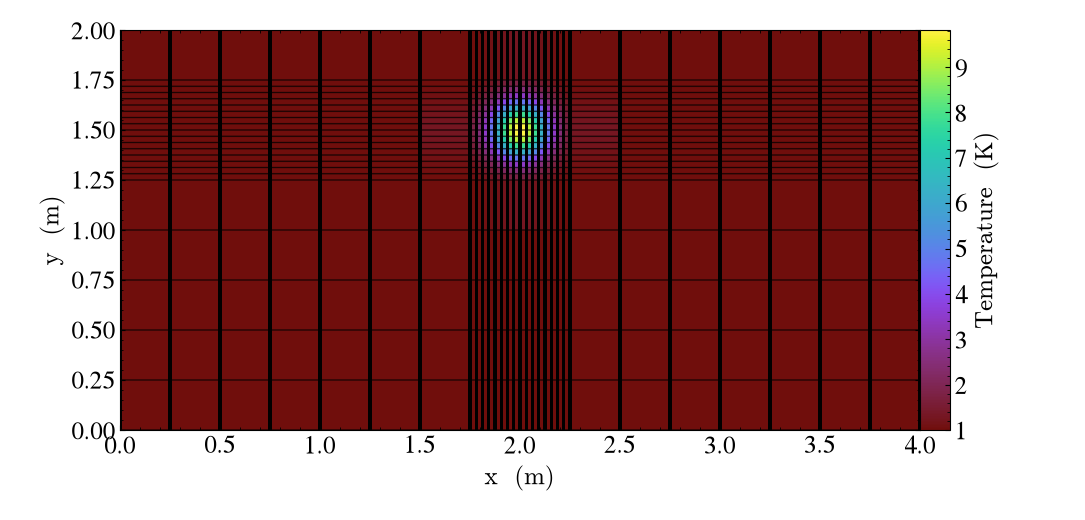

In [3]:
ds_yt = ds.yt.load_grid()
slc = yt.SlicePlot(ds_yt, "z", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_cell_edges()
slc.show()

This works for most of yt, but some consumers of yt datasets (yt_idv, for example) require every grid to have a constant cell spacing in each dimension.

## Loading as a uniform grid

`ds.yt.load_as_uniform_grid` builds a new uniform grid and interpolates the xarray fields onto it in native coordinates, on demand as yt reads data. By default the bounding box is the extent of the data and the cell spacing in each dimension is the *smallest* spacing of the stretched grid, so every feature of the original grid is resolved:

yt_xarray : [INFO ] 2026-10-22 15:45:46,549:  Using a cell_spacing of [0.03125 0.03125 0.125  ].
yt : [INFO     ] 2026-10-22 15:45:46,564 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:46,565 Parameters: domain_dimensions         = [128  64   8]
yt : [INFO     ] 2026-10-22 15:45:46,565 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-22 15:45:46,565 Parameters: domain_right_edge         = [4. 2. 1.]
yt : [INFO     ] 2026-10-22 15:45:46,565 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-10-22 15:45:46,597 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:46,597 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:46,597 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:46,597 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:46,598 Making a fixed resolution buffer of (('stream', 'temperature')) 800 by 800


domain dimensions: [128  64   8]
cell spacing: [0.03125 0.03125 0.125  ]



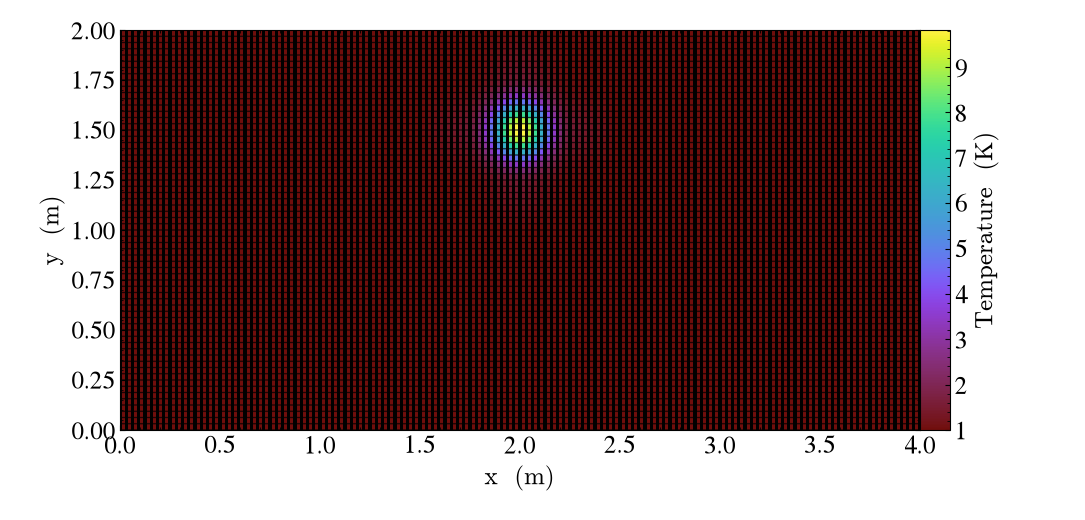

In [4]:
ds_uniform = ds.yt.load_as_uniform_grid()
print("domain dimensions:", ds_uniform.domain_dimensions)
print("cell spacing:", ds_uniform.index.grids[0].dds.d)

slc = yt.SlicePlot(ds_uniform, "z", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_cell_edges()
slc.show()

The bounding box and cell spacing can be set explicitly, by coordinate name. The bounding box may extend beyond the data, in which case cells outside the data are filled with `fill_value` (`np.nan` by default). If a bounding box width is not an integer multiple of the spacing, the maximum edge is extended so that it is:

yt : [INFO     ] 2026-10-22 15:45:46,846 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:46,847 Parameters: domain_dimensions         = [15 10  4]
yt : [INFO     ] 2026-10-22 15:45:46,847 Parameters: domain_left_edge          = [0.5 0.  0. ]
yt : [INFO     ] 2026-10-22 15:45:46,847 Parameters: domain_right_edge         = [3.5 2.  1. ]
yt : [INFO     ] 2026-10-22 15:45:46,848 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-10-22 15:45:46,883 xlim = 0.500000 3.500000
yt : [INFO     ] 2026-10-22 15:45:46,883 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:46,883 xlim = 0.500000 3.500000
yt : [INFO     ] 2026-10-22 15:45:46,884 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:46,884 Making a fixed resolution buffer of (('stream', 'temperature')) 800 by 800


domain dimensions: [15 10  4]



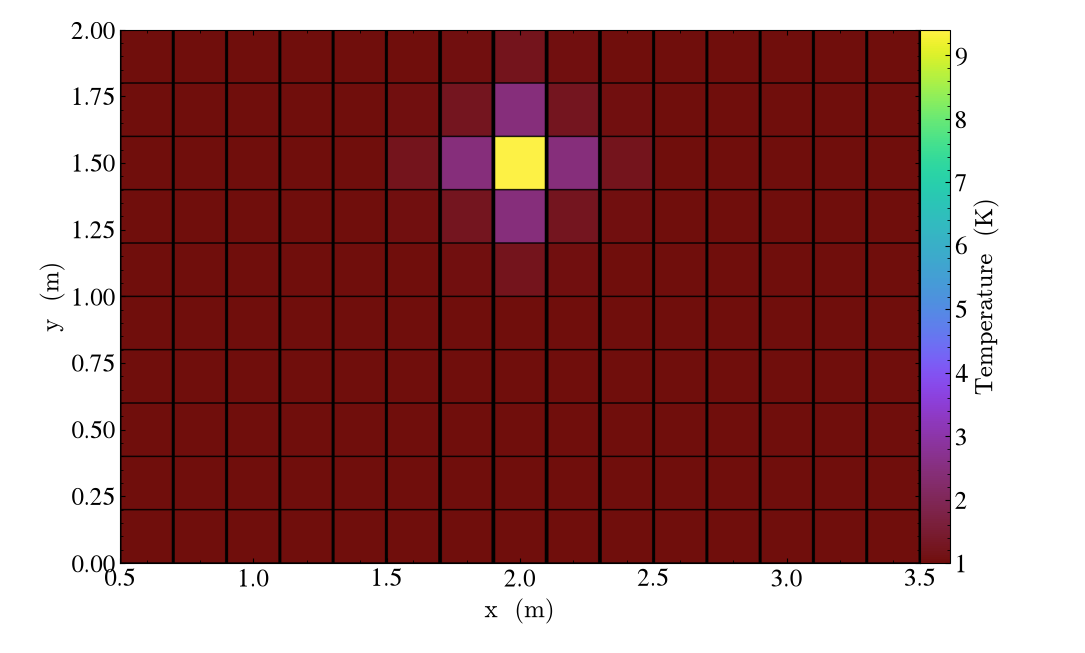

In [5]:
ds_coarse = ds.yt.load_as_uniform_grid(
    bbox={"x": (0.5, 3.5)},
    cell_spacing={"x": 0.2, "y": 0.2, "z": 0.25},
)
print("domain dimensions:", ds_coarse.domain_dimensions)

slc = yt.SlicePlot(ds_coarse, "z", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_cell_edges()
slc.show()

Like `load_grid`, the uniform grid can be split into multiple yt grids with `chunksizes`. The grid outlines can be drawn with the `annotate_grids` callback (the interpolated grid is not periodic, and `annotate_grids` defaults to drawing periodic images of the grids, so `periodic=False` is passed here):

yt_xarray : [INFO ] 2026-10-22 15:45:47,139:  Using a cell_spacing of [0.03125 0.03125 0.125  ].
yt_xarray : [INFO ] 2026-10-22 15:45:47,139:  Constructing a yt chunked grid with 8 chunks.
yt : [INFO     ] 2026-10-22 15:45:47,157 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:47,157 Parameters: domain_dimensions         = [128  64   8]
yt : [INFO     ] 2026-10-22 15:45:47,158 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-22 15:45:47,158 Parameters: domain_right_edge         = [4. 2. 1.]
yt : [INFO     ] 2026-10-22 15:45:47,158 Parameters: cosmological_simulation   = 0
yt : [INFO     ] 2026-10-22 15:45:47,202 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:47,203 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:47,203 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:47,203 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:47,204 Making a fixed resolution buffer of (('stream', 'temperatur

number of grids: 8



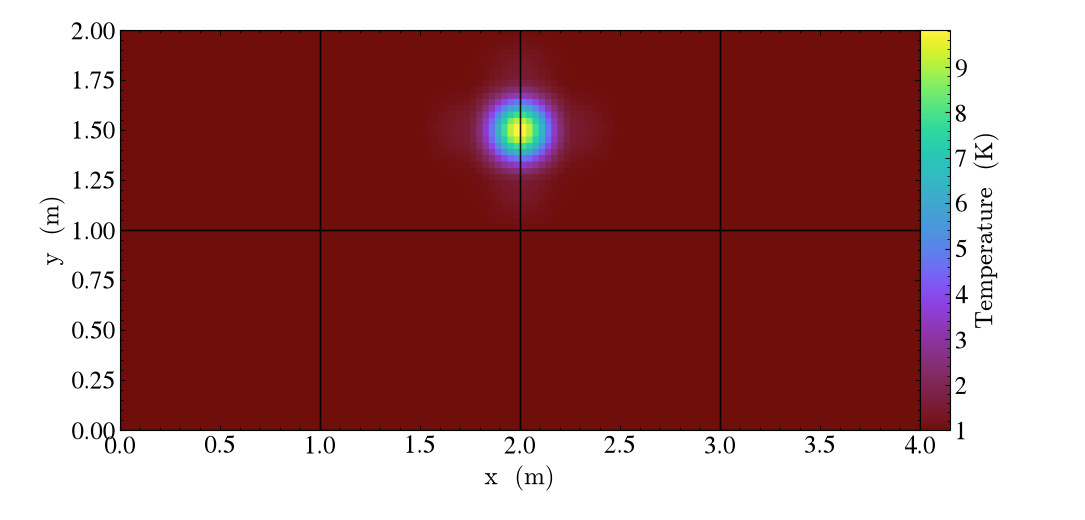

In [6]:
ds_chunked = ds.yt.load_as_uniform_grid(chunksizes=32)
print("number of grids:", len(ds_chunked.index.grids))

slc = yt.SlicePlot(ds_chunked, "z", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_grids(periodic=False)
slc.show()

## Loading as a refined hierarchy of uniform grids

Resampling at the smallest spacing everywhere is wasteful when the fine spacing is confined to a small region. With `refine_grid=True`, a coarse level 0 grid covers the whole domain and finer grids are added only where the stretched grid spacing is finer than the current level's spacing. The hierarchy is planned from the coordinate values of the stretched grid alone, so no field data is read until yt asks for it.

By default, the level 0 spacing is chosen so that the finest level lands exactly on the smallest spacing of the stretched grid:

yt_xarray : [INFO ] 2026-10-22 15:45:47,364:  Using a cell_spacing of [0.25  0.25  0.125].
yt_xarray : [INFO ] 2026-10-22 15:45:47,366:      level 0: 1 grids, 1024 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,366:      level 1: 3 grids, 2816 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,370:      level 2: 5 grids, 22528 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,370:      level 3: 5 grids, 180224 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,371:  Refined grid plan has 206592 cells in 14 grids. A uniform grid at the finest source spacing would have 65536 cells.
yt : [INFO     ] 2026-10-22 15:45:47,384 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:47,384 Parameters: domain_dimensions         = [16  8  8]
yt : [INFO     ] 2026-10-22 15:45:47,385 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-22 15:45:47,385 Parameters: domain_right_edge         = [4. 2. 1.]
yt : [INFO     ] 2026-10-22 15:45:47,385 Parameters: cosmological_s

level 0 dimensions: [16  8  8]


yt : [INFO     ] 2026-10-22 15:45:47,440 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:47,441 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:47,441 xlim = 0.000000 4.000000
yt : [INFO     ] 2026-10-22 15:45:47,441 ylim = 0.000000 2.000000
yt : [INFO     ] 2026-10-22 15:45:47,442 Making a fixed resolution buffer of (('stream', 'temperature')) 800 by 800


max level: 3



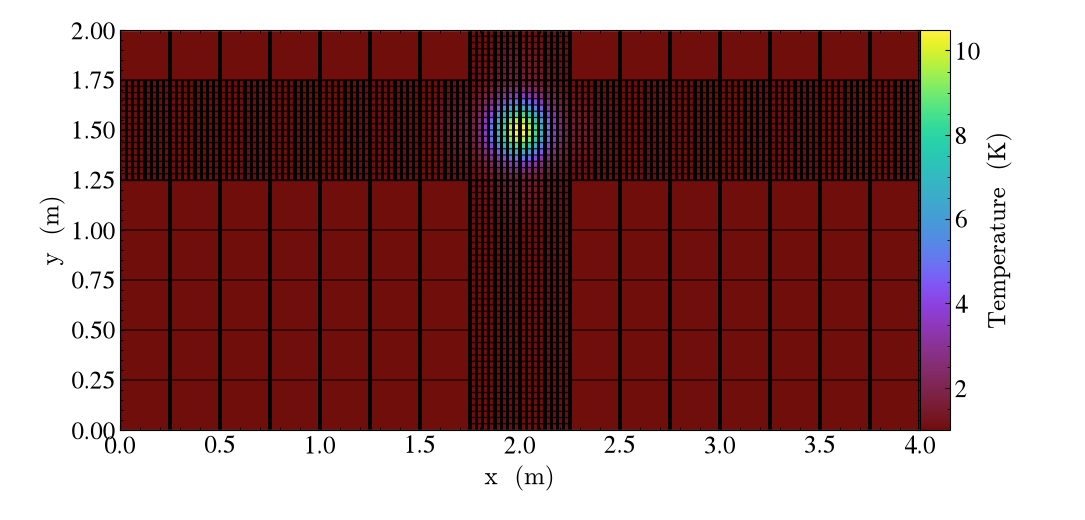

In [7]:
ds_refined = ds.yt.load_as_uniform_grid(refine_grid=True)

print("level 0 dimensions:", ds_refined.domain_dimensions)
print("max level:", ds_refined.index.max_level)

slc = yt.SlicePlot(ds_refined, "z", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_cell_edges()
slc.annotate_grids(periodic=False)
slc.show()

The refined grids cover the bands where `x` or `y` are finely spaced. Note that yt refines all dimensions together, so those bands are also refined in `z`, even though the stretched grid is uniform in `z`. For this dataset that costs more cells than the uniform grid did:

In [8]:
def n_cells(ds_yt):
    return sum(g.ActiveDimensions.prod() for g in ds_yt.index.grids)


def print_levels(ds_yt):
    for level in range(ds_yt.index.max_level + 1):
        grids = [g for g in ds_yt.index.grids if g.Level == level]
        print(f"level {level}: {len(grids)} grids, {sum(g.ActiveDimensions.prod() for g in grids)} cells")
    print(f"total: {n_cells(ds_yt)} cells (uniform grid: {n_cells(ds_uniform)} cells)")


print_levels(ds_refined)

level 0: 1 grids, 1024 cells
level 1: 3 grids, 2816 cells
level 2: 5 grids, 22528 cells
level 3: 5 grids, 180224 cells
total: 206592 cells (uniform grid: 65536 cells)


For a grid that is only stretched in some dimensions, `refine_by` can be given per dimension as a dictionary keyed by coordinate name (so you don't need to know the internal dimension order). A refinement factor of 1 means that dimension is never refined, and the level 0 spacing in that dimension defaults to the smallest spacing of the stretched grid. Slicing along `x` through the center of the domain shows the `y`-`z` plane: cells are refined in `y` but keep the coarse spacing in `z`:

yt_xarray : [INFO ] 2026-10-22 15:45:47,642:  Using a cell_spacing of [0.25  0.25  0.125].
yt_xarray : [INFO ] 2026-10-22 15:45:47,647:      level 0: 1 grids, 1024 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,647:      level 1: 3 grids, 1408 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,648:      level 2: 5 grids, 5632 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,648:      level 3: 5 grids, 22528 cells
yt_xarray : [INFO ] 2026-10-22 15:45:47,700:  Refined grid plan has 30592 cells in 14 grids. A uniform grid at the finest source spacing would have 65536 cells.
yt : [INFO     ] 2026-10-22 15:45:47,713 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-10-22 15:45:47,714 Parameters: domain_dimensions         = [16  8  8]
yt : [INFO     ] 2026-10-22 15:45:47,714 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-22 15:45:47,714 Parameters: domain_right_edge         = [4. 2. 1.]
yt : [INFO     ] 2026-10-22 15:45:47,714 Parameters: cosmological_simu

level 0: 1 grids, 1024 cells
level 1: 3 grids, 1408 cells
level 2: 5 grids, 5632 cells
level 3: 5 grids, 22528 cells
total: 30592 cells (uniform grid: 65536 cells)



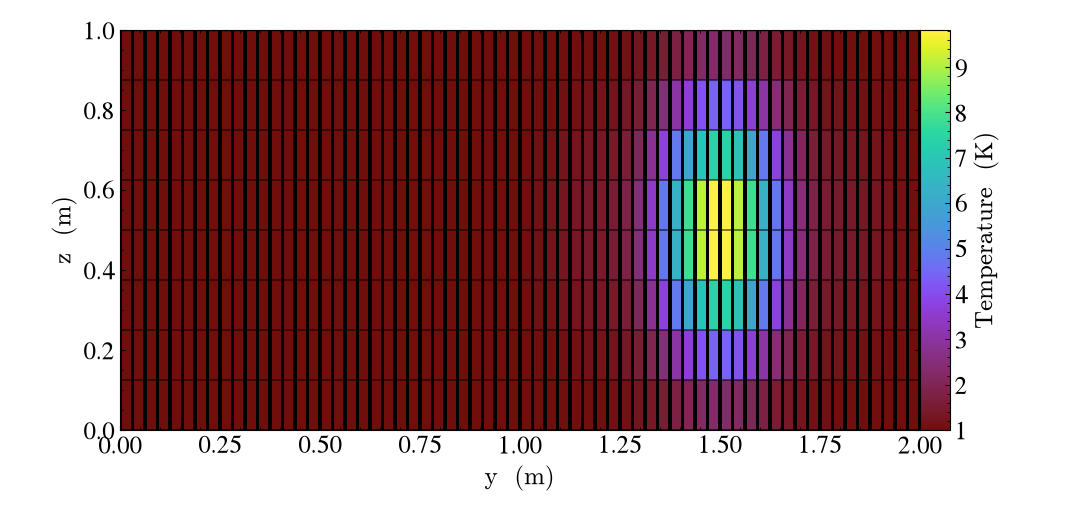

In [9]:
ds_aniso = ds.yt.load_as_uniform_grid(refine_grid=True, refine_by={"x": 2, "y": 2, "z": 1})
print_levels(ds_aniso)

slc = yt.SlicePlot(ds_aniso, "x", ("stream", "temperature"), origin="native")
slc.set_log(("stream", "temperature"), False)
slc.annotate_cell_edges()
slc.annotate_grids(periodic=False)
slc.show()

The savings grow as the finely spaced region shrinks relative to the domain. The loader logs the same cell count comparison when it builds the hierarchy, so it is easy to check whether refinement is worthwhile for a given dataset.

The `max_level` argument caps the depth of the hierarchy, and `cell_spacing` sets the level 0 spacing when `refine_grid=True`. Any grid-based yt functionality works as usual on the resulting datasets, e.g., a covering grid at the finest level:

In [10]:
cg = ds_aniso.covering_grid(
    ds_aniso.index.max_level,
    ds_aniso.domain_left_edge,
    ds_aniso.domain_dimensions * np.array([2, 2, 1]) ** ds_aniso.index.max_level,
)
cg[("stream", "temperature")].shape

(128, 64, 8)